Part 0 — Setup and the Data  

In [1]:
pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv('Dataset/healthcare-dataset-stroke-data_1.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [5]:
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (5110, 12)
Total Rows: 5110
Total Columns: 12


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [7]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [8]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0])

Missing Values:
bmi    201
dtype: int64


In [9]:
missing_percentage = ( df.isnull().sum() / len(df)) * 100

print(missing_percentage[missing_percentage > 0])

bmi    3.933464
dtype: float64


In [10]:
print("Gender Distribution:")

print(df['gender'].value_counts())

Gender Distribution:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64


In [11]:
print("Stroke Distribution:")

print(df['stroke'].value_counts())

Stroke Distribution:
stroke
0    4861
1     249
Name: count, dtype: int64


In [12]:
stroke_counts = df['stroke'].value_counts()

stroke_percentages = (df['stroke'].value_counts(normalize=True) * 100)

distribution = pd.DataFrame({
    'Count': stroke_counts,
    'Percentage': stroke_percentages
})

print(distribution)

        Count  Percentage
stroke                   
0        4861   95.127202
1         249    4.872798


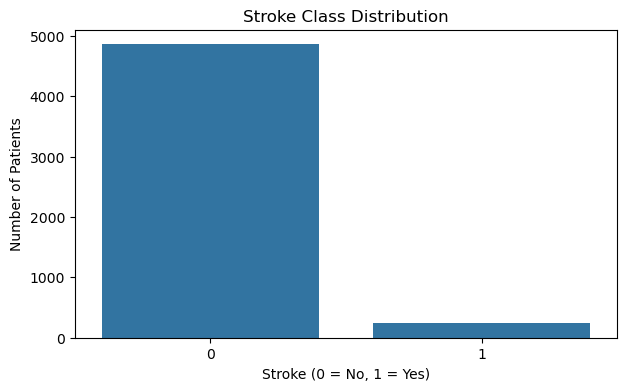

In [13]:
plt.figure(figsize=(7, 4))

sns.countplot(data = df, x = 'stroke')

plt.title('Stroke Class Distribution')
plt.xlabel('Stroke (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')

plt.show()

In [14]:
df = df.drop(columns=['id'])

print("ID column removed successfully!")

ID column removed successfully!


In [15]:
df = df[df['gender'] != 'Other'].copy()

print("Updated Dataset Shape:", df.shape)
print(df['gender'].value_counts())

Updated Dataset Shape: (5109, 11)
gender
Female    2994
Male      2115
Name: count, dtype: int64


In [16]:
X = df.drop(columns=['stroke'])

y = df['stroke']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (5109, 10)
Target Shape: (5109,)


In [17]:
categorical_columns = X.select_dtypes(include=['object']).columns

print("Categorical Columns:")

print(categorical_columns.tolist())

Categorical Columns:
['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


In [18]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoding Completed!")
print("Encoded Features Shape:", X.shape)

X.head()

Encoding Completed!
Encoded Features Shape: (5109, 15)


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,1,0,1,0,0,1,1,0,0
1,61.0,0,0,202.21,NaN,0,1,0,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,1,1,0,1,0,0,0,0,1,0
3,49.0,0,0,171.23,34.4,0,1,0,1,0,0,1,0,0,1
4,79.0,1,0,174.12,24.0,0,1,0,0,1,0,0,0,1,0


In [19]:
SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (4087, 15)
Testing Features: (1022, 15)
Training Target: (4087,)
Testing Target: (1022,)


In [20]:
bmi_median = X_train['bmi'].median()

X_train['bmi'] = X_train['bmi'].fillna(bmi_median)

X_test['bmi'] = X_test['bmi'].fillna(bmi_median)

print("Missing values handled successfully!")

print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())

Missing values handled successfully!
Training missing values: 0
Testing missing values: 0


In [21]:
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

print("Feature Scaling Completed!")

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Feature Scaling Completed!
Scaled Training Shape: (4087, 15)
Scaled Testing Shape: (1022, 15)


In [22]:
print("Training Means:")
print(X_train_scaled.mean().round(2))

print("\nTraining Standard Deviations:")
print(X_train_scaled.std().round(2))

Training Means:
age                              -0.0
hypertension                     -0.0
heart_disease                     0.0
avg_glucose_level                 0.0
bmi                              -0.0
gender_Male                       0.0
ever_married_Yes                 -0.0
work_type_Never_worked            0.0
work_type_Private                 0.0
work_type_Self-employed          -0.0
work_type_children                0.0
Residence_type_Urban              0.0
smoking_status_formerly smoked    0.0
smoking_status_never smoked      -0.0
smoking_status_smokes             0.0
dtype: float64

Training Standard Deviations:
age                               1.0
hypertension                      1.0
heart_disease                     1.0
avg_glucose_level                 1.0
bmi                               1.0
gender_Male                       1.0
ever_married_Yes                  1.0
work_type_Never_worked            1.0
work_type_Private                 1.0
work_type_Self-employed   

In [23]:
print("Training Stroke Distribution:")
print(y_train.value_counts())

print("\nTesting Stroke Distribution:")
print(y_test.value_counts())

Training Stroke Distribution:
stroke
0    3888
1     199
Name: count, dtype: int64

Testing Stroke Distribution:
stroke
0    972
1     50
Name: count, dtype: int64


The dataset is highly imbalanced, containing 4,861 non-stroke patients (95.13%) and only 249 stroke patients (4.87%). We used stratify=y to maintain approximately the same class distribution in the training and testing sets. If the test set contains too few stroke cases, the evaluation metrics, particularly recall, may become unreliable and may not accurately represent the model's performance.

Part 1 — The Accuracy Trap  

Task 1.1 — Build a baseline model

In [24]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline_model = DummyClassifier(strategy='most_frequent')

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print("Baseline Model Accuracy:", baseline_accuracy)
print("Baseline Model Accuracy (%):", baseline_accuracy * 100)

Baseline Model Accuracy: 0.9510763209393346
Baseline Model Accuracy (%): 95.10763209393346


Task 1.2 — Train Logistic Regression

In [25]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression()

lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

lr_probabilities = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def evaluate_model(model, X_train, X_test, y_train, y_test):

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    results = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, y_prob),
        'PR AUC': average_precision_score(y_test, y_prob)
    }

    return results

In [27]:
lr_results = evaluate_model(
    LogisticRegression(),
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

print("Logistic Regression Results:\n")

for metric, value in lr_results.items():
    print(f"{metric}: {value:.4f}")

Logistic Regression Results:

Accuracy: 0.9521
Precision: 1.0000
Recall: 0.0200
F1 Score: 0.0392
ROC AUC: 0.8394
PR AUC: 0.2692


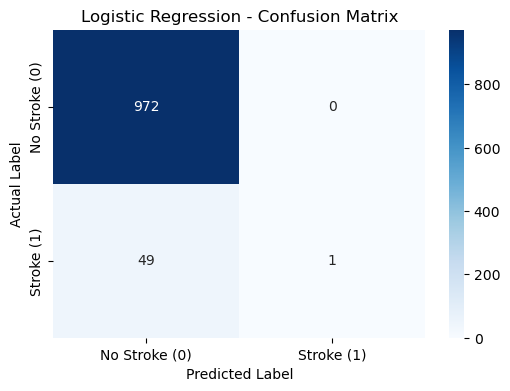

In [28]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

lr_predictions = lr_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Stroke (0)', 'Stroke (1)'],
    yticklabels=['No Stroke (0)', 'Stroke (1)']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [29]:
comparison = pd.DataFrame({
    'Model': ['Baseline Model', 'Logistic Regression'],
    'Accuracy': [
        baseline_accuracy,
        lr_results['Accuracy']
    ]
})

print(comparison)

                 Model  Accuracy
0       Baseline Model  0.951076
1  Logistic Regression  0.952055


(a) Compare the accuracy of the baseline and Logistic Regression. What do you conclude?

The Baseline Model achieved 95.11% accuracy, while Logistic Regression achieved 95.21%. Although Logistic Regression performed slightly better, its high accuracy is misleading because the dataset is highly imbalanced. Therefore, accuracy alone cannot determine model performance.

(b) What does a false negative mean in the hospital's situation, and which numbers should we trust instead of accuracy?

A false negative means an actual stroke patient is incorrectly predicted as having no stroke. In a hospital, this could cause a patient to miss timely medical attention. We should focus on Recall, Precision, F1-score, ROC AUC, PR AUC and the confusion matrix, particularly recall, to evaluate stroke detection performance.

Part 2 — Underfitting, Overfitting, Bias and Variance  

Task 2.1 — Validation Curve

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    validation_curve,
    StratifiedKFold
)

SEED = 42

In [31]:
depths = list(range(1, 16)) + [None]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

In [32]:
tree = DecisionTreeClassifier(random_state=SEED)

train_scores, cv_scores = validation_curve(
    tree,
    X_train,
    y_train,
    param_name='max_depth',
    param_range=depths,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

validation_results = pd.DataFrame({
    'Max Depth': [str(d) for d in depths],
    'Training ROC AUC': train_mean,
    'CV ROC AUC': cv_mean
})

print(validation_results)

   Max Depth  Training ROC AUC  CV ROC AUC
0          1          0.752304    0.731666
1          2          0.828284    0.816755
2          3          0.847048    0.816109
3          4          0.865828    0.818040
4          5          0.889965    0.792089
5          6          0.914956    0.758513
6          7          0.937748    0.738470
7          8          0.957291    0.713760
8          9          0.974830    0.681188
9         10          0.987531    0.641388
10        11          0.993332    0.610807
11        12          0.996701    0.612583
12        13          0.998262    0.595539
13        14          0.999074    0.588883
14        15          0.999486    0.577850
15      None          1.000000    0.564415


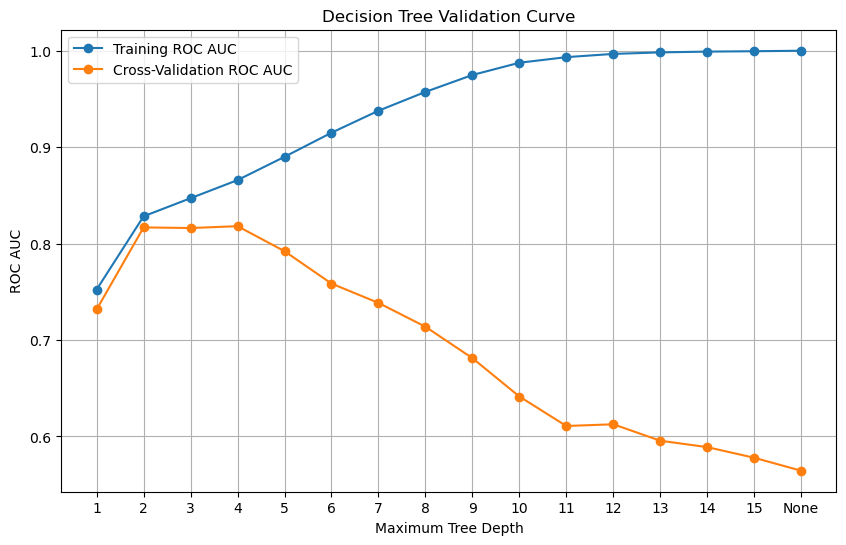

In [33]:
plt.figure(figsize=(10, 6))

x_labels = [str(d) for d in depths]

plt.plot(
    x_labels,
    train_mean,
    marker='o',
    label='Training ROC AUC'
)

plt.plot(
    x_labels,
    cv_mean,
    marker='o',
    label='Cross-Validation ROC AUC'
)

plt.xlabel('Maximum Tree Depth')
plt.ylabel('ROC AUC')
plt.title('Decision Tree Validation Curve')
plt.legend()
plt.grid(True)
plt.show()

In [34]:
best_index = np.argmax(cv_mean)

best_depth = depths[best_index]
best_auc = cv_mean[best_index]

print("Best Max Depth:", best_depth)
print("Best Cross-Validation ROC AUC:", best_auc)

Best Max Depth: 4
Best Cross-Validation ROC AUC: 0.8180403159452002


Task 2.2 — Learning Curves

In [35]:
from sklearn.model_selection import learning_curve

In [36]:
train_sizes = np.linspace(0.2, 1.0, 5)

print("Training sizes:", train_sizes)

Training sizes: [0.2 0.4 0.6 0.8 1. ]


In [37]:
def plot_learning_curve(depth, ax, title):

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=SEED
    )

    sizes, train_scores, valid_scores = learning_curve(
        model,
        X_train,
        y_train,
        train_sizes=train_sizes,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )

    train_mean = train_scores.mean(axis=1)
    valid_mean = valid_scores.mean(axis=1)

    ax.plot(
        sizes,
        train_mean,
        marker='o',
        label='Training ROC AUC'
    )

    ax.plot(
        sizes,
        valid_mean,
        marker='o',
        label='CV ROC AUC'
    )

    ax.set_title(title)
    ax.set_xlabel('Number of Training Rows')
    ax.set_ylabel('ROC AUC')
    ax.legend()
    ax.grid(True)

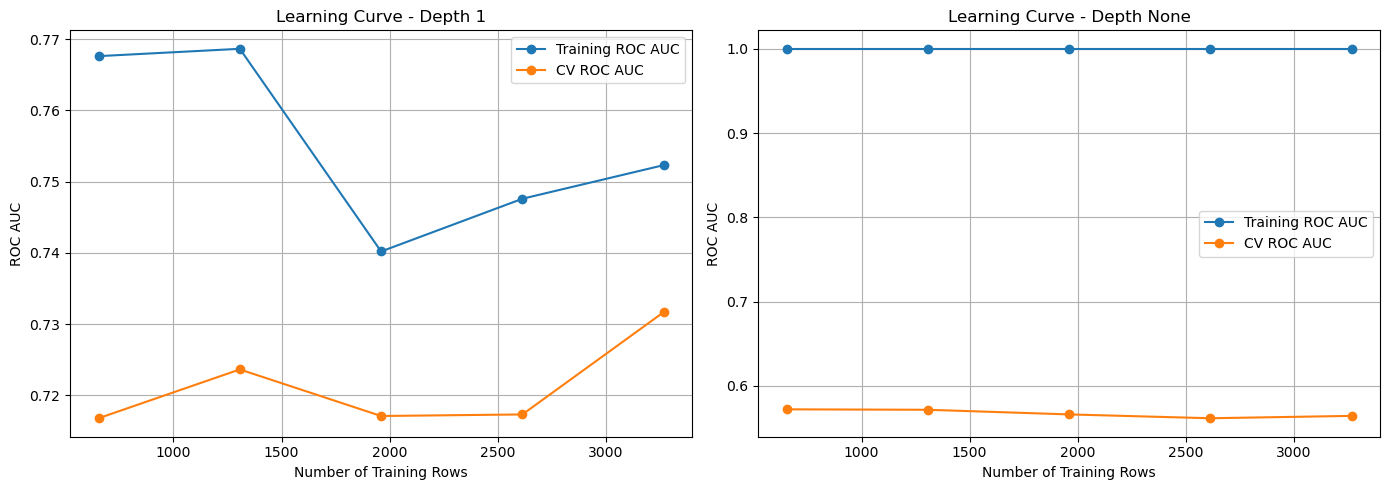

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_learning_curve(
    1,
    axes[0],
    'Learning Curve - Depth 1'
)

plot_learning_curve(
    None,
    axes[1],
    'Learning Curve - Depth None'
)

plt.tight_layout()
plt.show()

Task 2.3 — Measure Variance Directly

In [39]:
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(SEED)

In [40]:
depth_values = [1, 3, None]

variance_results = []

for depth in depth_values:

    all_probabilities = []
    individual_aucs = []

    for i in range(40):

        idx = rng.choice(
            len(X_train),
            size=len(X_train),
            replace=True
        )

        X_bootstrap = X_train.iloc[idx]
        y_bootstrap = y_train.iloc[idx]

        model = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED + i
        )

        model.fit(X_bootstrap, y_bootstrap)

        probabilities = model.predict_proba(X_test)[:, 1]

        all_probabilities.append(probabilities)

        auc = roc_auc_score(y_test, probabilities)
        individual_aucs.append(auc)

    all_probabilities = np.array(all_probabilities)

    patient_variances = all_probabilities.var(axis=0)

    mean_variance = patient_variances.mean()

    mean_auc = np.mean(individual_aucs)

    average_probabilities = all_probabilities.mean(axis=0)

    average_auc = roc_auc_score(
        y_test,
        average_probabilities
    )

    variance_results.append({
        'Max Depth': str(depth),
        'Mean Prediction Variance': mean_variance,
        'Mean Test ROC AUC': mean_auc,
        'AUC of Averaged Predictions': average_auc
    })

In [41]:
variance_df = pd.DataFrame(variance_results)

print(variance_df.round(4))

  Max Depth  Mean Prediction Variance  Mean Test ROC AUC  \
0         1                    0.0007             0.7623   
1         3                    0.0017             0.7964   
2      None                    0.0418             0.5545   

   AUC of Averaged Predictions  
0                       0.8132  
1                       0.8340  
2                       0.7534  


(a) From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone.

Depth 1 underfits, with training AUC of 0.7523 and CV AUC of 0.7317. Depths 5 onwards increasingly overfit; for example, depth 10 has training AUC of 0.9875 and CV AUC of 0.6414. I would choose depth 4 because it achieves the highest CV AUC of 0.8180, with training AUC of 0.8658.

(b) From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one?

High bias occurs when training and CV scores are both low and close together, as seen with depth 1. High variance occurs when training performance is very high but CV performance is much lower, as seen with depth None. Adding more training data can help reduce high variance, but it usually cannot fix high bias alone.

(c) From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4).

Prediction variance increases with depth: 0.0007 for depth 1, 0.0017 for depth 3 and 0.0418 for unlimited depth. Averaging predictions improves ROC AUC compared with the mean individual-tree AUC for all three depths. This demonstrates how Random Forest combines multiple trees to reduce prediction instability and improve generalization.

(d) In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?

The bias-variance trade-off is the balance between a model being too simple and too complex. Depth 1 has high bias and underfits, depth 3 provides a better balance with low variance, while depth None has high variance and overfits.

Part 3 — ROC, AUC, Precision-Recall and Thresholds  

Task 3.1 — Compare models with curves

In [42]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

In [43]:
lr_model = LogisticRegression()

lr_model.fit(X_train_scaled, y_train)

dt_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=SEED
)

dt_model.fit(X_train, y_train)

rf_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("All three models trained successfully!")

All three models trained successfully!


In [44]:
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]

dt_probs = dt_model.predict_proba(X_test)[:, 1]

rf_probs = rf_model.predict_proba(X_test)[:, 1]

print("Prediction probabilities generated successfully!")

Prediction probabilities generated successfully!


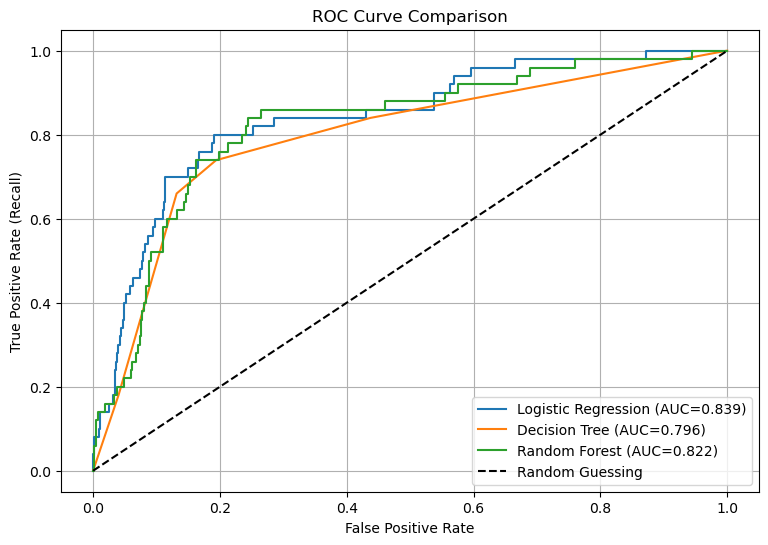

In [45]:
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
dt_fpr, dt_tpr, _ = roc_curve(y_test, dt_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)

lr_auc = roc_auc_score(y_test, lr_probs)
dt_auc = roc_auc_score(y_test, dt_probs)
rf_auc = roc_auc_score(y_test, rf_probs)

plt.figure(figsize=(9, 6))

plt.plot(
    lr_fpr, lr_tpr,
    label=f'Logistic Regression (AUC={lr_auc:.3f})'
)

plt.plot(
    dt_fpr, dt_tpr,
    label=f'Decision Tree (AUC={dt_auc:.3f})'
)

plt.plot(
    rf_fpr, rf_tpr,
    label=f'Random Forest (AUC={rf_auc:.3f})'
)

plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(True)
plt.show()

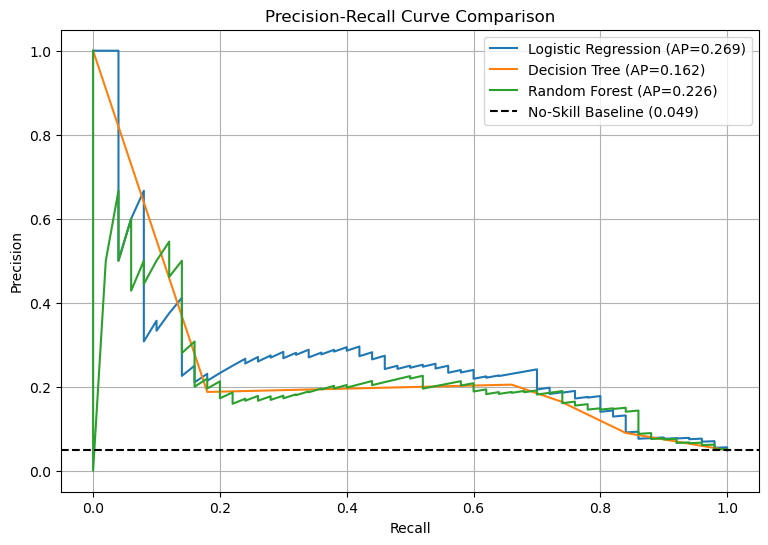

In [46]:
lr_precision, lr_recall, _ = precision_recall_curve(y_test, lr_probs)

dt_precision, dt_recall, _ = precision_recall_curve(y_test, dt_probs)

rf_precision, rf_recall, _ = precision_recall_curve(y_test, rf_probs)

lr_ap = average_precision_score(y_test, lr_probs)
dt_ap = average_precision_score(y_test, dt_probs)
rf_ap = average_precision_score(y_test, rf_probs)

no_skill = y_test.mean()

plt.figure(figsize=(9, 6))

plt.plot(
    lr_recall, lr_precision,
    label=f'Logistic Regression (AP={lr_ap:.3f})'
)

plt.plot(
    dt_recall, dt_precision,
    label=f'Decision Tree (AP={dt_ap:.3f})'
)

plt.plot(
    rf_recall, rf_precision,
    label=f'Random Forest (AP={rf_ap:.3f})'
)

plt.axhline(
    y=no_skill,
    color='black',
    linestyle='--',
    label=f'No-Skill Baseline ({no_skill:.3f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')
plt.legend()
plt.grid(True)
plt.show()

In [47]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'ROC AUC': [
        lr_auc,
        dt_auc,
        rf_auc
    ],
    'PR AUC': [
        lr_ap,
        dt_ap,
        rf_ap
    ]
})

print(model_comparison.round(4))

                 Model  ROC AUC  PR AUC
0  Logistic Regression   0.8394  0.2692
1        Decision Tree   0.7956  0.1621
2        Random Forest   0.8224  0.2255


Task 3.2 — Choose a decision threshold

In [48]:
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

oof_probabilities = cross_val_predict(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

print("Out-of-fold probabilities generated successfully!")

Out-of-fold probabilities generated successfully!


In [49]:
from sklearn.metrics import precision_recall_curve

oof_precision, oof_recall, thresholds = precision_recall_curve(
    y_train,
    oof_probabilities
)

eligible_thresholds = thresholds[oof_recall[:-1] >= 0.80]

best_threshold = eligible_thresholds.max()

print("Selected Threshold:", best_threshold)

Selected Threshold: 0.05091645209675615


In [50]:
lr_pipeline.fit(X_train, y_train)

test_probabilities = lr_pipeline.predict_proba(X_test)[:, 1]

threshold_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Test predictions generated successfully!")

Test predictions generated successfully!


In [51]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_precision = precision_score(
    y_test,
    threshold_predictions,
    zero_division=0
)

threshold_recall = recall_score(
    y_test,
    threshold_predictions,
    zero_division=0
)

threshold_f1 = f1_score(
    y_test,
    threshold_predictions,
    zero_division=0
)

threshold_cm = confusion_matrix(
    y_test,
    threshold_predictions
)

flagged_patients = threshold_predictions.sum()

false_alarms = threshold_cm[0, 1]

missed_strokes = threshold_cm[1, 0]

print("Selected Threshold:", best_threshold)
print("Test Precision:", threshold_precision)
print("Test Recall:", threshold_recall)
print("Test F1 Score:", threshold_f1)

print("\nConfusion Matrix:")
print(threshold_cm)

print("\nTotal Flagged Patients:", flagged_patients)
print("False Alarms:", false_alarms)
print("Missed Stroke Patients:", missed_strokes)

Selected Threshold: 0.05091645209675615
Test Precision: 0.1353135313531353
Test Recall: 0.82
Test F1 Score: 0.23229461756373937

Confusion Matrix:
[[710 262]
 [  9  41]]

Total Flagged Patients: 303
False Alarms: 262
Missed Stroke Patients: 9


(a) In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression was much higher than 0.5. How can both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?
Logistic Regression achieved a ROC AUC of 0.8394 but only 2% recall at the default threshold of 0.5. This is possible because ROC AUC measures the model's ability to rank positive cases above negative cases across different thresholds, whereas recall of 2% measures performance at only the 0.5 threshold. Lowering the threshold can identify more positive cases and increase recall.
(b) Which metric curve is more informative for this data — ROC or Precision-Recall — and why? Use the no-skill line in your answer.
The Precision-Recall curve is more informative because our dataset is highly imbalanced, with only approximately 4.9% stroke patients. Its no-skill baseline is 0.049. Logistic Regression achieved an Average Precision of 0.2692, Random Forest 0.2255, and Decision Tree 0.1621, all above the baseline. The Precision-Recall curve focuses on the minority positive class.
(c) At your chosen threshold, what is the price the hospital pays for the higher recall? Is it acceptable? Argue both sides in 3–4 lines.
At the selected threshold of 0.0509, recall increased to 82%, identifying 41 out of 50 stroke patients and missing only 9. However, the model flagged 303 patients, including 262 false alarms, resulting in only 13.53% precision. This may be acceptable for initial screening because fewer stroke patients are missed, but it increases unnecessary medical examinations, costs and patient anxiety. The final decision should consider the hospital's resources and medical requirements.

Part 4: Undersampling, Oversampling and SMOTE

In [ ]:
Task 4.1 — Compare the methods

In [52]:
print("Original training dataset shape:", X_train.shape)

print("\nOriginal training class distribution:")
print(y_train.value_counts())

print("\nOriginal test dataset shape:", X_test.shape)

print("\nOriginal test class distribution:")
print(y_test.value_counts())

Original training dataset shape: (4087, 15)

Original training class distribution:
stroke
0    3888
1     199
Name: count, dtype: int64

Original test dataset shape: (1022, 15)

Original test class distribution:
stroke
0    972
1     50
Name: count, dtype: int64


In [53]:
resamplers = {
    'No Resampling': None,

    'Random Undersampling': RandomUnderSampler(
        random_state=SEED
    ),

    'Random Oversampling': RandomOverSampler(
        random_state=SEED
    ),

    'SMOTE': SMOTE(
        random_state=SEED
    )
}

In [54]:
def evaluate_resampled_model(model, X_train_data, y_train_data,
                             X_test_data, y_test_data):

    model.fit(X_train_data, y_train_data)

    predictions = model.predict(X_test_data)

    probabilities = model.predict_proba(X_test_data)[:, 1]

    return {
        'Precision': precision_score(
            y_test_data, predictions, zero_division=0
        ),

        'Recall': recall_score(
            y_test_data, predictions, zero_division=0
        ),

        'F1': f1_score(
            y_test_data, predictions, zero_division=0
        ),

        'ROC AUC': roc_auc_score(
            y_test_data, probabilities
        ),

        'PR AUC': average_precision_score(
            y_test_data, probabilities
        )
    }

In [55]:
results = []

for method_name, sampler in resamplers.items():

    if sampler is None:
        X_resampled = X_train_scaled.copy()
        y_resampled = y_train.copy()

    else:
        X_resampled, y_resampled = sampler.fit_resample(
            X_train_scaled,
            y_train
        )

    model = LogisticRegression(
        random_state=SEED,
        max_iter=1000
    )

    metrics = evaluate_resampled_model(
        model,
        X_resampled,
        y_resampled,
        X_test_scaled,
        y_test
    )

    results.append({
        'Model': 'Logistic Regression',
        'Method': method_name,
        'Training Rows': len(y_resampled),
        'Training Stroke Cases': int(
            (y_resampled == 1).sum()
        ),
        **metrics
    })

print("Logistic Regression experiments completed!")

Logistic Regression experiments completed!


In [56]:
for method_name, sampler in resamplers.items():

    if sampler is None:
        X_resampled = X_train.copy()
        y_resampled = y_train.copy()

    else:
        X_resampled, y_resampled = sampler.fit_resample(
            X_train,
            y_train
        )

    model = RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED,
        n_jobs=-1
    )

    metrics = evaluate_resampled_model(
        model,
        X_resampled,
        y_resampled,
        X_test,
        y_test
    )

    results.append({
        'Model': 'Random Forest',
        'Method': method_name,
        'Training Rows': len(y_resampled),
        'Training Stroke Cases': int(
            (y_resampled == 1).sum()
        ),
        **metrics
    })

print("Random Forest experiments completed!")

Random Forest experiments completed!


In [57]:
lr_balanced = LogisticRegression(
    class_weight='balanced',
    random_state=SEED,
    max_iter=1000
)

lr_balanced_results = evaluate_resampled_model(
    lr_balanced,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

results.append({
    'Model': 'Logistic Regression',
    'Method': 'Class Weight Balanced',
    'Training Rows': len(y_train),
    'Training Stroke Cases': int((y_train == 1).sum()),
    **lr_balanced_results
})

In [58]:
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=SEED,
    n_jobs=-1
)

rf_balanced_results = evaluate_resampled_model(
    rf_balanced,
    X_train,
    y_train,
    X_test,
    y_test
)

results.append({
    'Model': 'Random Forest',
    'Method': 'Class Weight Balanced',
    'Training Rows': len(y_train),
    'Training Stroke Cases': int((y_train == 1).sum()),
    **rf_balanced_results
})

In [59]:
results_df = pd.DataFrame(results)

results_df = results_df[
    [
        'Model',
        'Method',
        'Training Rows',
        'Training Stroke Cases',
        'Precision',
        'Recall',
        'F1',
        'ROC AUC',
        'PR AUC'
    ]
]

print(results_df.round(4))

                 Model                 Method  Training Rows  \
0  Logistic Regression          No Resampling           4087   
1  Logistic Regression   Random Undersampling            398   
2  Logistic Regression    Random Oversampling           7776   
3  Logistic Regression                  SMOTE           7776   
4        Random Forest          No Resampling           4087   
5        Random Forest   Random Undersampling            398   
6        Random Forest    Random Oversampling           7776   
7        Random Forest                  SMOTE           7776   
8  Logistic Regression  Class Weight Balanced           4087   
9        Random Forest  Class Weight Balanced           4087   

   Training Stroke Cases  Precision  Recall      F1  ROC AUC  PR AUC  
0                    199     1.0000    0.02  0.0392   0.8394  0.2692  
1                    199     0.1246    0.82  0.2164   0.8352  0.2338  
2                   3888     0.1333    0.80  0.2286   0.8385  0.2646  
3          

Task 4.2 — The Classic Mistake: Data Leakage

In [60]:
X_all = X.copy()
y_all = y.copy()

X_all['bmi'] = X_all['bmi'].fillna(
    X_all['bmi'].median()
)

print("Complete dataset shape:", X_all.shape)
print("Missing values:", X_all.isnull().sum().sum())

Complete dataset shape: (5109, 15)
Missing values: 0


In [61]:
smote_wrong = SMOTE(random_state=SEED)

X_smote_wrong, y_smote_wrong = smote_wrong.fit_resample(
    X_all,
    y_all
)

print("Dataset shape after SMOTE:", X_smote_wrong.shape)

print("\nClass distribution after SMOTE:")
print(y_smote_wrong.value_counts())

Dataset shape after SMOTE: (9720, 15)

Class distribution after SMOTE:
stroke
1    4860
0    4860
Name: count, dtype: int64


In [62]:
from sklearn.model_selection import train_test_split

X_train_wrong, X_test_wrong, y_train_wrong, y_test_wrong = (
    train_test_split(
        X_smote_wrong,
        y_smote_wrong,
        test_size=0.2,
        random_state=SEED,
        stratify=y_smote_wrong
    )
)

print("Wrong training shape:", X_train_wrong.shape)
print("Wrong testing shape:", X_test_wrong.shape)

Wrong training shape: (7776, 15)
Wrong testing shape: (1944, 15)


In [63]:
rf_wrong = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=-1
)

rf_wrong.fit(X_train_wrong, y_train_wrong)

wrong_predictions = rf_wrong.predict(X_test_wrong)

wrong_probabilities = rf_wrong.predict_proba(X_test_wrong)[:, 1]

In [64]:
wrong_results = {
    'Precision': precision_score(
        y_test_wrong,
        wrong_predictions,
        zero_division=0
    ),

    'Recall': recall_score(
        y_test_wrong,
        wrong_predictions,
        zero_division=0
    ),

    'F1': f1_score(
        y_test_wrong,
        wrong_predictions,
        zero_division=0
    ),

    'ROC AUC': roc_auc_score(
        y_test_wrong,
        wrong_probabilities
    ),

    'PR AUC': average_precision_score(
        y_test_wrong,
        wrong_probabilities
    )
}

print(pd.Series(wrong_results).round(4))

Precision    0.9290
Recall       0.9424
F1           0.9356
ROC AUC      0.9811
PR AUC       0.9761
dtype: float64


In [65]:
correct_smote_result = results_df[
    (results_df['Model'] == 'Random Forest') &
    (results_df['Method'] == 'SMOTE')
].iloc[0]

smote_comparison = pd.DataFrame([
    {
        'Method': 'Correct SMOTE (After Split)',
        **{
            metric: correct_smote_result[metric]
            for metric in ['Precision', 'Recall', 'F1', 'ROC AUC', 'PR AUC']
        }
    },
    {
        'Method': 'Wrong SMOTE (Before Split)',
        **wrong_results
    }
])

print(smote_comparison.round(4))

                        Method  Precision  Recall      F1  ROC AUC  PR AUC
0  Correct SMOTE (After Split)     0.1266  0.2000  0.1550   0.7668  0.1187
1   Wrong SMOTE (Before Split)     0.9290  0.9424  0.9356   0.9811  0.9761


(a) For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision and ROC AUC across the methods and explain why.
Resampling significantly improved Logistic Regression's recall from 2% to 80–82%. However, precision decreased from 100% to approximately 12–13%. ROC AUC remained relatively stable, between 0.8352 and 0.8406. Resampling helps the model learn the minority class, but it can increase false positives. ROC AUC changes less because it evaluates ranking performance across different thresholds.
(b) Did Random Forest react to the methods in the same way as Logistic Regression? Describe one clear difference and give one possible reason.
No. Random Forest achieved 84% recall with undersampling, but only 20% with SMOTE. Logistic Regression achieved 80% recall with SMOTE. Random Forest responds differently because decision trees learn nonlinear splits and interactions, while Logistic Regression learns a linear decision boundary. Resampling can therefore affect their decision boundaries differently.
(c) Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted? Explain what leaks from where.
Correct SMOTE achieved 0.7668 ROC AUC and 0.1187 PR AUC, while incorrect SMOTE achieved 0.9811 ROC AUC and 0.9761 PR AUC. The incorrect method applied SMOTE before splitting, allowing information from future test observations to influence synthetic training samples. This causes data leakage and overly optimistic results, so the incorrect results cannot be trusted.
(d) If you had to pick one rebalancing approach for this hospital, which would you pick and why? Consider simplicity and the cost of each choice.
I would choose Logistic Regression with class_weight='balanced' because it achieved 80% recall, 13.47% precision and 0.8395 ROC AUC. It does not require removing observations or generating synthetic samples, making it simple and computationally efficient. Although Logistic Regression with SMOTE achieved a higher PR AUC of 0.2876, class weighting provides a good balance between performance and simplicity.

Part 5: Noisy Data

Task 5.1 — Label Noise

In [66]:
def create_models(seed=42):

    return {
        'Logistic Regression': LogisticRegression(
            max_iter=1000,
            random_state=seed
        ),

        'Decision Tree (Depth 3)': DecisionTreeClassifier(
            max_depth=3,
            random_state=seed
        ),

        'Decision Tree (None)': DecisionTreeClassifier(
            max_depth=None,
            random_state=seed
        ),

        'Random Forest': RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=5,
            random_state=seed,
            n_jobs=-1
        )
    }

In [67]:
def add_label_noise(y, noise_fraction, seed):

    rng = np.random.default_rng(seed)

    y_noisy = y.copy().to_numpy()

    n_flip = int(round(len(y_noisy) * noise_fraction))

    flip_indices = rng.choice(
        len(y_noisy),
        size=n_flip,
        replace=False
    )

    y_noisy[flip_indices] = 1 - y_noisy[flip_indices]

    return pd.Series(
        y_noisy,
        index=y.index,
        name=y.name
    )

In [68]:
noise_levels = [0, 0.05, 0.10, 0.20]

label_noise_results = []

for noise_level in noise_levels:

    repeats = 1 if noise_level == 0 else 5

    repeat_scores = {
        model_name: []
        for model_name in create_models()
    }

    for repeat in range(repeats):

        y_noisy = add_label_noise(
            y_train,
            noise_level,
            seed=SEED + repeat
        )

        scaler = StandardScaler()

        X_train_scaled_noise = scaler.fit_transform(X_train)
        X_test_scaled_noise = scaler.transform(X_test)

        models = create_models(SEED + repeat)

        for model_name, model in models.items():

            if model_name == 'Logistic Regression':
                X_fit = X_train_scaled_noise
                X_eval = X_test_scaled_noise

            else:
                X_fit = X_train
                X_eval = X_test

            model.fit(X_fit, y_noisy)

            probabilities = model.predict_proba(X_eval)[:, 1]

            auc = roc_auc_score(
                y_test,
                probabilities
            )

            repeat_scores[model_name].append(auc)

    row = {'Noise Fraction': noise_level}

    for model_name, scores in repeat_scores.items():
        row[model_name] = np.mean(scores)

    label_noise_results.append(row)

print("Label noise experiment completed!")

Label noise experiment completed!


In [69]:
label_noise_df = pd.DataFrame(label_noise_results)

print(label_noise_df.round(4))

   Noise Fraction  Logistic Regression  Decision Tree (Depth 3)  \
0            0.00               0.8394                   0.7956   
1            0.05               0.8241                   0.8014   
2            0.10               0.8133                   0.8029   
3            0.20               0.7743                   0.7260   

   Decision Tree (None)  Random Forest  
0                0.5797         0.8224  
1                0.5429         0.7999  
2                0.5065         0.7601  
3                0.4982         0.6786  


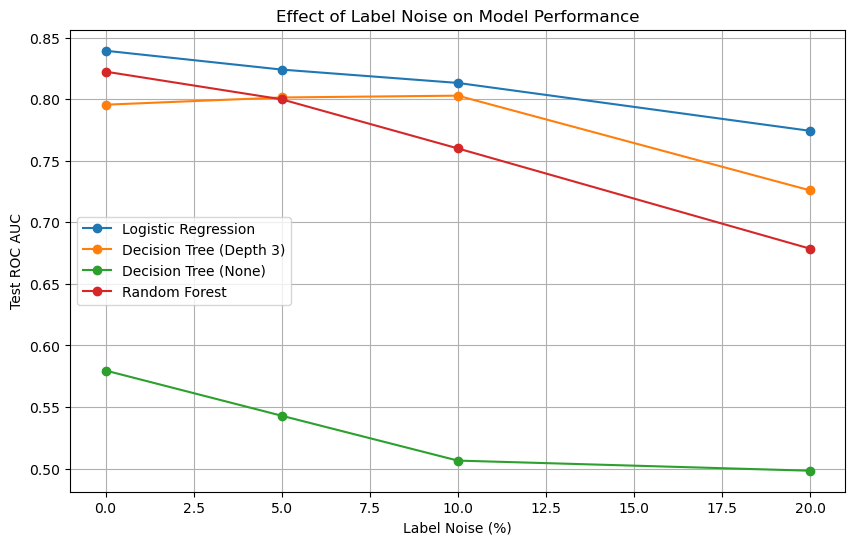

In [70]:
plt.figure(figsize=(10, 6))

for model_name in label_noise_df.columns[1:]:

    plt.plot(
        label_noise_df['Noise Fraction'] * 100,
        label_noise_df[model_name],
        marker='o',
        label=model_name
    )

plt.xlabel('Label Noise (%)')
plt.ylabel('Test ROC AUC')
plt.title('Effect of Label Noise on Model Performance')

plt.legend()
plt.grid(True)
plt.show()

Task 5.2 — Feature Noise

In [71]:
def add_feature_noise(X, noise_level, seed):

    rng = np.random.default_rng(seed)

    X_noisy = X.copy()

    noisy_columns = [
        'age',
        'avg_glucose_level',
        'bmi'
    ]

    for column in noisy_columns:

        column_std = X[column].std()

        noise = (
            rng.normal(0, 1, size=len(X))
            * column_std
            * noise_level
        )

        X_noisy[column] = X_noisy[column] + noise

    return X_noisy

In [72]:
feature_noise_levels = [0, 0.5, 1, 2]

feature_noise_results = []

for noise_level in feature_noise_levels:

    repeat_scores = {
        model_name: []
        for model_name in create_models()
    }

    for repeat in range(5):

        X_train_noisy = add_feature_noise(
            X_train,
            noise_level,
            seed=SEED + repeat
        )

        scaler = StandardScaler()

        X_train_scaled_noise = scaler.fit_transform(
            X_train_noisy
        )

        X_test_scaled_noise = scaler.transform(X_test)

        models = create_models(SEED + repeat)

        for model_name, model in models.items():

            if model_name == 'Logistic Regression':

                X_fit = X_train_scaled_noise
                X_eval = X_test_scaled_noise

            else:

                X_fit = X_train_noisy
                X_eval = X_test

            model.fit(X_fit, y_train)

            probabilities = model.predict_proba(X_eval)[:, 1]

            auc = roc_auc_score(
                y_test,
                probabilities
            )

            repeat_scores[model_name].append(auc)

    row = {'Noise Level': noise_level}

    for model_name, scores in repeat_scores.items():
        row[model_name] = np.mean(scores)

    feature_noise_results.append(row)

print("Feature noise experiment completed!")

Feature noise experiment completed!


In [73]:
feature_noise_df = pd.DataFrame(feature_noise_results)

print(feature_noise_df.round(4))

   Noise Level  Logistic Regression  Decision Tree (Depth 3)  \
0          0.0               0.8394                   0.7956   
1          0.5               0.8337                   0.7995   
2          1.0               0.8098                   0.7610   
3          2.0               0.7695                   0.6942   

   Decision Tree (None)  Random Forest  
0                0.5775         0.8218  
1                0.5605         0.8112  
2                0.5287         0.7891  
3                0.5288         0.7481  


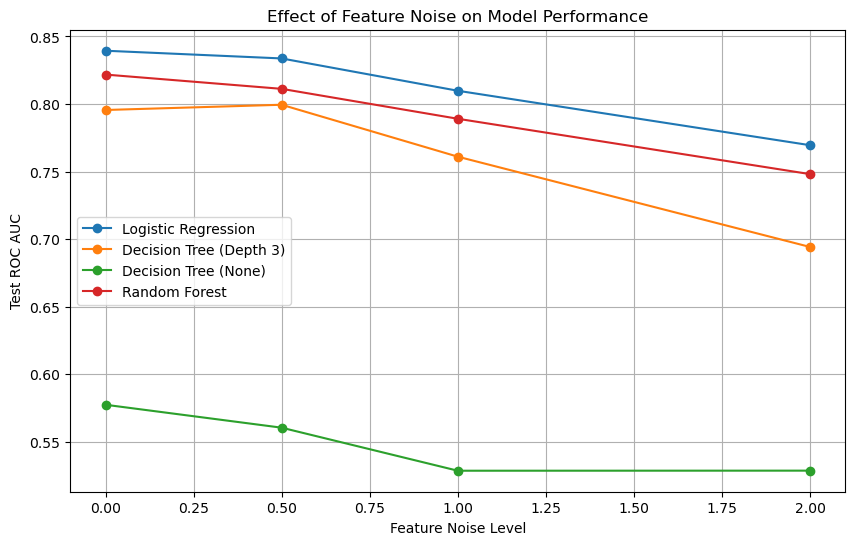

In [74]:
plt.figure(figsize=(10, 6))

for model_name in feature_noise_df.columns[1:]:

    plt.plot(
        feature_noise_df['Noise Level'],
        feature_noise_df[model_name],
        marker='o',
        label=model_name
    )

plt.xlabel('Feature Noise Level')
plt.ylabel('Test ROC AUC')
plt.title('Effect of Feature Noise on Model Performance')

plt.legend()
plt.grid(True)
plt.show()

Task 5.3 — SMOTE and Noisy Labels

In [75]:
smote_noise_results = []

for repeat in range(3):

    y_noisy = add_label_noise(
        y_train,
        noise_fraction=0.10,
        seed=SEED + repeat
    )

    scaler = StandardScaler()

    X_train_scaled_noise = scaler.fit_transform(X_train)
    X_test_scaled_noise = scaler.transform(X_test)

    lr_X_train = X_train_scaled_noise
    lr_X_test = X_test_scaled_noise

    rf_X_train = X_train.copy()
    rf_X_test = X_test.copy()

    smote_lr = SMOTE(random_state=SEED + repeat)

    X_lr_smote, y_lr_smote = smote_lr.fit_resample(
        lr_X_train,
        y_noisy
    )

    smote_rf = SMOTE(random_state=SEED + repeat)

    X_rf_smote, y_rf_smote = smote_rf.fit_resample(
        rf_X_train,
        y_noisy
    )

    models = {
        'Logistic Regression': {
            'original': (lr_X_train, y_noisy, lr_X_test),
            'smote': (X_lr_smote, y_lr_smote, lr_X_test),
            'model_class': LogisticRegression
        },

        'Random Forest': {
            'original': (rf_X_train, y_noisy, rf_X_test),
            'smote': (X_rf_smote, y_rf_smote, rf_X_test),
            'model_class': RandomForestClassifier
        }
    }

    for model_name, settings in models.items():

        for method in ['original', 'smote']:

            X_fit, y_fit, X_eval = settings[method]

            if model_name == 'Logistic Regression':

                model = LogisticRegression(
                    max_iter=1000,
                    random_state=SEED + repeat
                )

            else:

                model = RandomForestClassifier(
                    n_estimators=200,
                    min_samples_leaf=5,
                    random_state=SEED + repeat,
                    n_jobs=-1
                )

            model.fit(X_fit, y_fit)

            probabilities = model.predict_proba(X_eval)[:, 1]

            smote_noise_results.append({
                'Repeat': repeat + 1,
                'Model': model_name,
                'Method': 'With SMOTE' if method == 'smote'
                          else 'Without SMOTE',

                'ROC AUC': roc_auc_score(
                    y_test,
                    probabilities
                ),

                'PR AUC': average_precision_score(
                    y_test,
                    probabilities
                )
            })

print("SMOTE with noisy labels experiment completed!")

SMOTE with noisy labels experiment completed!


In [76]:
smote_noise_results = []

for repeat in range(3):

    y_noisy = add_label_noise(
        y_train,
        noise_fraction=0.10,
        seed=SEED + repeat
    )

    scaler = StandardScaler()

    X_train_scaled_noise = scaler.fit_transform(X_train)
    X_test_scaled_noise = scaler.transform(X_test)

    lr_X_train = X_train_scaled_noise
    lr_X_test = X_test_scaled_noise

    rf_X_train = X_train.copy()
    rf_X_test = X_test.copy()

    smote_lr = SMOTE(random_state=SEED + repeat)

    X_lr_smote, y_lr_smote = smote_lr.fit_resample(
        lr_X_train,
        y_noisy
    )

    smote_rf = SMOTE(random_state=SEED + repeat)

    X_rf_smote, y_rf_smote = smote_rf.fit_resample(
        rf_X_train,
        y_noisy
    )

    models = {
        'Logistic Regression': {
            'original': (lr_X_train, y_noisy, lr_X_test),
            'smote': (X_lr_smote, y_lr_smote, lr_X_test),
            'model_class': LogisticRegression
        },

        'Random Forest': {
            'original': (rf_X_train, y_noisy, rf_X_test),
            'smote': (X_rf_smote, y_rf_smote, rf_X_test),
            'model_class': RandomForestClassifier
        }
    }

    for model_name, settings in models.items():

        for method in ['original', 'smote']:

            X_fit, y_fit, X_eval = settings[method]

            if model_name == 'Logistic Regression':

                model = LogisticRegression(
                    max_iter=1000,
                    random_state=SEED + repeat
                )

            else:

                model = RandomForestClassifier(
                    n_estimators=200,
                    min_samples_leaf=5,
                    random_state=SEED + repeat,
                    n_jobs=-1
                )

            model.fit(X_fit, y_fit)

            probabilities = model.predict_proba(X_eval)[:, 1]

            smote_noise_results.append({
                'Repeat': repeat + 1,
                'Model': model_name,
                'Method': 'With SMOTE' if method == 'smote'
                          else 'Without SMOTE',

                'ROC AUC': roc_auc_score(
                    y_test,
                    probabilities
                ),

                'PR AUC': average_precision_score(
                    y_test,
                    probabilities
                )
            })

print("SMOTE with noisy labels experiment completed!")

SMOTE with noisy labels experiment completed!


In [77]:
smote_noise_df = pd.DataFrame(smote_noise_results)

print(smote_noise_df.round(4))

    Repeat                Model         Method  ROC AUC  PR AUC
0        1  Logistic Regression  Without SMOTE   0.8190  0.2221
1        1  Logistic Regression     With SMOTE   0.8196  0.2165
2        1        Random Forest  Without SMOTE   0.7310  0.1526
3        1        Random Forest     With SMOTE   0.5848  0.0588
4        2  Logistic Regression  Without SMOTE   0.8104  0.2426
5        2  Logistic Regression     With SMOTE   0.8218  0.2563
6        2        Random Forest  Without SMOTE   0.7515  0.1264
7        2        Random Forest     With SMOTE   0.5810  0.0585
8        3  Logistic Regression  Without SMOTE   0.8125  0.1874
9        3  Logistic Regression     With SMOTE   0.8160  0.2064
10       3        Random Forest  Without SMOTE   0.7658  0.2058
11       3        Random Forest     With SMOTE   0.6291  0.0635


In [78]:
smote_noise_summary = (
    smote_noise_df
    .groupby(['Model', 'Method'])[
        ['ROC AUC', 'PR AUC']
    ]
    .mean()
    .reset_index()
)

print(smote_noise_summary.round(4))

                 Model         Method  ROC AUC  PR AUC
0  Logistic Regression     With SMOTE   0.8191  0.2264
1  Logistic Regression  Without SMOTE   0.8140  0.2174
2        Random Forest     With SMOTE   0.5983  0.0603
3        Random Forest  Without SMOTE   0.7494  0.1616


(a) Which model is most damaged by noise and which is most stable? Quote numbers at the highest noise level and explain using what you learned in Part 2.
At 20% label noise, Random Forest was most damaged: its ROC AUC decreased from 0.8224 to 0.6786. Logistic Regression was most stable, decreasing from 0.8394 to 0.7743. At feature noise level 2, Decision Tree (depth 3) experienced the largest drop, from 0.7956 to 0.6942. This supports Part 2's finding that model complexity and variance affect sensitivity to changes in training data. The unrestricted Decision Tree also had high variance and poor overall performance.
(b) Which hurts more here — label noise or feature noise of a comparable level? Give a short reason.
Label noise generally hurt more in our experiments. At the highest noise levels, Random Forest ROC AUC dropped from 0.8224 to 0.6786 with label noise, compared with 0.8218 to 0.7481 with feature noise. Incorrect labels directly corrupt the target information, making it harder for models to learn the correct relationship between features and classes.
(c) What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.
SMOTE slightly improved Logistic Regression, increasing ROC AUC from 0.8140 to 0.8191 and PR AUC from 0.2174 to 0.2264. However, it significantly damaged Random Forest, decreasing ROC AUC from 0.7494 to 0.5983 and PR AUC from 0.1616 to 0.0603. SMOTE can amplify label noise because it treats incorrectly labeled minority samples as genuine and generates additional synthetic samples around them, spreading incorrect class information.

Part 6 — Final Decision and Conclusion

Task 6.1 — Compare default and selected thresholds

In [79]:
default_predictions = (
    test_probabilities >= 0.5
).astype(int)

selected_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Predictions generated successfully!")

Predictions generated successfully!


In [80]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def calculate_final_metrics(y_true, predictions):

    cm = confusion_matrix(y_true, predictions)

    return {
        'Precision': precision_score(
            y_true, predictions, zero_division=0
        ),

        'Recall': recall_score(
            y_true, predictions, zero_division=0
        ),

        'F1': f1_score(
            y_true, predictions, zero_division=0
        ),

        'False Alarms': cm[0, 1],

        'Missed Strokes': cm[1, 0]
    }


default_results = calculate_final_metrics(
    y_test,
    default_predictions
)

selected_results = calculate_final_metrics(
    y_test,
    selected_predictions
)

In [81]:
final_comparison = pd.DataFrame([
    {
        'Approach': 'Default Threshold (0.5)',
        **default_results
    },
    {
        'Approach': f'Selected Threshold ({best_threshold:.4f})',
        **selected_results
    }
])

print(final_comparison.round(4))

                      Approach  Precision  Recall      F1  False Alarms  \
0      Default Threshold (0.5)     1.0000    0.02  0.0392             0   
1  Selected Threshold (0.0509)     0.1353    0.82  0.2323           262   

   Missed Strokes  
0              49  
1               9  


Task 6.2 — Executive Summary

This lab investigated bias, variance, class imbalance and noisy data using the Stroke Prediction dataset. I selected Logistic Regression with a decision threshold of 0.0509 as the final approach. It achieved 82% recall and 13.53% precision, identifying 41 out of 50 stroke patients. The model produced 262 false alarms and missed 9 stroke patients. I avoided data leakage by fitting preprocessing steps and selecting the threshold using training data only, while keeping the test set untouched. A major limitation is that the test set contains only 50 stroke patients, so even a small change in predictions can affect recall considerably. The selected threshold also involves a trade-off between detecting more stroke patients and increasing false alarms.

(a) What was the most surprising result in this lab?
The most surprising result was that Logistic Regression achieved 95.21% accuracy but only 2% recall at the default threshold. After lowering the threshold to 0.0509, recall increased to 82%. This demonstrated that accuracy can be misleading on highly imbalanced datasets.
(b) If you had one more hour, what would you try next?
I would experiment with different threshold values, hyperparameter tuning and ensemble methods. I would also test the selected approach using more medical data to check whether its high recall can be maintained with fewer false alarms.